# Phase 5: Advanced NLP & Transformer-Based Classification
## Intelligent Consumer Complaint Classification & Prioritization Using NLP

This notebook orchestrates our Phase 5 transformer experimentation, evaluating pretrained contextual language models against the Phase 4 traditional ML baseline (`LinearSVC` on `text_stopword` Word TF-IDF).

### Objectives
1. Assess available compute hardware and design a resource-aware transformer experiment matrix.
2. Analyze subword tokenization and sequence-length truncation trade-offs (`128`, `256`, `512`).
3. Fine-tune and compare multiple pretrained transformer architectures (`BERT-mini`, `ELECTRA-small`, `MiniLM-L6`, `DistilBERT-base`) on `text_minimal`.
4. Evaluate class-weighted loss (`standard` vs. `weighted`) and learning-rate tuning strictly on the stratified validation split.
5. Select the best transformer by **validation Macro-F1**, evaluate it **once** on the held-out test set (`n = 1,635`), perform error analysis and Gradient × Input token attribution, and compare directly against Phase 4.

## 2. Previous Phase Results (Phases 1–3 Summary)

- **Phase 1:** Acquired `liri-uzh/cfpb-complaints-mini` (`6,469` raw train, `1,635` raw test).
- **Phase 2:** Confirmed 7 balanced classes, right-skewed lengths (median `153` words), `~86%` redaction prevalence, and `0` train-test overlap.
- **Phase 3:** Removed `7` conflicting-label rows and `99` exact duplicates from `train` (`6,363` clean rows), kept `test` untouched (`1,635` rows), and created 5 normalized text columns (`text_minimal`, `text_standard`, `text_stopword`, `text_lemmatized`, `text_stemmed`).

## 3. Classical ML Baseline (Phase 4 Fixed Benchmark)

| Metric | Phase 4 `LinearSVC` (`text_stopword`) |
|---|---:|
| 5-Fold CV Macro-F1 | `0.8452 ± 0.0073` |
| Held-Out Test Macro-F1 | **`0.8512`** |
| Held-Out Test Accuracy | **`0.8508`** (`1,391 / 1,635`) |
| Held-Out Test Weighted-F1 | **`0.8512`** |

## 4. Dataset Overview

In [1]:
import json
import shutil
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path("..").resolve()
if not (PROJECT_ROOT / "data" / "processed").exists():
    PROJECT_ROOT = Path("Experiment_9/complaint-classification").resolve()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation.transformer_evaluation import (
    build_baseline_vs_transformer_table,
    load_phase4_baseline_benchmark,
)
from src.transformers.dataset import (
    ComplaintTorchDataset,
    EXPECTED_LABELS,
    ID2LABEL,
    LABEL2ID,
    create_stratified_split,
    decode_labels,
    encode_labels,
    load_processed_datasets,
)
from src.transformers.error_analysis import (
    build_error_analysis_dataframe,
    compare_with_baseline_errors,
)
from src.transformers.experiment_runner import run_experiments
from src.transformers.inference import TransformerComplaintClassifier
from src.transformers.interpretability import compute_token_attributions
from src.transformers.metrics import build_detailed_evaluation, compute_classification_metrics
from src.transformers.tokenizer_utils import compute_token_length_stats, load_tokenizer
from src.transformers.trainer import predict_with_model
from src.utils.hardware_detection import detect_hardware
from src.utils.reproducibility import set_global_seed

## 5. Hardware and Resource Assessment

In [2]:
hw_info = detect_hardware(PROJECT_ROOT)
for k, v in hw_info.items():
    print(f"{k:24s}: {v}")

pytorch_version         : 2.2.1+cpu
device                  : cpu
cuda_available          : False
cuda_version            : None
gpu_count               : 0
gpu_names               : []
gpu_vram_gb             : []
fp16_supported          : False
bf16_supported          : False
recommended_precision   : fp32
recommended_batch_size  : 16
cpu_cores_logical       : 16
ram_total_gb            : 15.63
ram_available_gb        : 3.21
disk_free_gb            : 165.75
runtime_note            : No CUDA GPU detected (CPU-only PyTorch). Running in FP32 with dynamic padding, lightweight/distilled transformer backbones, and compact sequence lengths for feasible CPU runtime.


## 6. Configuration & Plotting Setup

In [3]:
RANDOM_STATE = 42
set_global_seed(RANDOM_STATE)

sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300

DATA_PROC_DIR = PROJECT_ROOT / "data" / "processed"
REPORTS_TR_DIR = PROJECT_ROOT / "reports" / "transformers"
FIGURES_TR_DIR = PROJECT_ROOT / "reports" / "figures" / "transformers"
MODELS_TR_DIR = PROJECT_ROOT / "models" / "transformers"
CONFIG_PATH = PROJECT_ROOT / "configs" / "transformer_experiments.yaml"

for d in (REPORTS_TR_DIR, FIGURES_TR_DIR, MODELS_TR_DIR):
    d.mkdir(parents=True, exist_ok=True)

## 7. Deterministic Label Mapping

In [4]:
print("LABEL2ID:", LABEL2ID)
print("ID2LABEL:", ID2LABEL)

LABEL2ID: {'bank_account': 0, 'credit_card': 1, 'credit_reporting': 2, 'debt_collection': 3, 'money_transfer': 4, 'mortgage': 5, 'student_loan': 6}
ID2LABEL: {0: 'bank_account', 1: 'credit_card', 2: 'credit_reporting', 3: 'debt_collection', 4: 'money_transfer', 5: 'mortgage', 6: 'student_loan'}


## 8. Dataset Integrity Checks

In [5]:
df_train, df_test, integrity = load_processed_datasets(DATA_PROC_DIR, text_col="text_minimal")
display(pd.DataFrame([integrity["train"], integrity["test"]]))
print(f"Train-Test Raw Overlap: {integrity['train_test_overlap']}")

,name,rows,null_labels,empty_texts,unexpected_labels,duplicate_text_label_pairs
0,train_processed,6363,0,0,[],34
1,test_processed,1635,0,0,[],6


Train-Test Raw Overlap: 0


## 9. Stratified Train-Validation Split (80/20, `random_state=42`)

All model selection, sequence length comparisons, class-weight tests, and hyperparameter tuning use only `train_sub` (`5,090` rows) and `val_sub` (`1,273` rows). `df_test` (`1,635` rows) remains isolated.

In [6]:
train_sub, val_sub = create_stratified_split(df_train, val_size=0.2, random_state=RANDOM_STATE)
split_df = pd.DataFrame({
    "Train Sub": train_sub["label"].value_counts().sort_index(),
    "Val Sub": val_sub["label"].value_counts().sort_index(),
    "Held-Out Test": df_test["label"].value_counts().sort_index(),
})
display(split_df)

,Train Sub,Val Sub,Held-Out Test
label,,,
bank_account,768,192,240
credit_card,678,170,219
credit_reporting,600,150,216
debt_collection,741,185,240
money_transfer,767,192,240
mortgage,768,192,240
student_loan,768,192,240


## 10. Transformer Architecture & Input Strategy Overview

We use `text_minimal` (preserving natural casing, punctuation, negation words, and `[REDACTED]` tokens) across four pretrained Hugging Face architectures selected for our CPU-only hardware profile:
1. `prajjwal1/bert-mini` (4 layers, 256 hidden, ~11.2M params) — fast baseline & length/loss ablation
2. `google/electra-small-discriminator` (12 layers, 256 hidden, ~13.5M params) — replaced-token-detection pretraining
3. `sentence-transformers/all-MiniLM-L6-v2` (6 layers, 384 hidden, ~22.7M params) — distilled sentence-semantic encoder
4. `distilbert-base-uncased` (6 layers, 768 hidden, ~66.9M params) — larger distilled BERT benchmark (`L=128`, 2 epochs due to CPU runtime)

## 11–12. Tokenization & Sequence Length Analysis (`text_minimal`)

We inspect subword token counts on `train_sub` without truncation across `max_length` = `128`, `256`, and `512`.

{'num_texts': 5090, 'mean_tokens': 290.28, 'median_tokens': 202.0, 'p90_tokens': 593.0, 'p95_tokens': 816.2, 'max_tokens': 6934, 'min_tokens': 5, 'truncation_pct_by_max_length': {128: 68.31, 256: 39.39, 512: 13.28}}


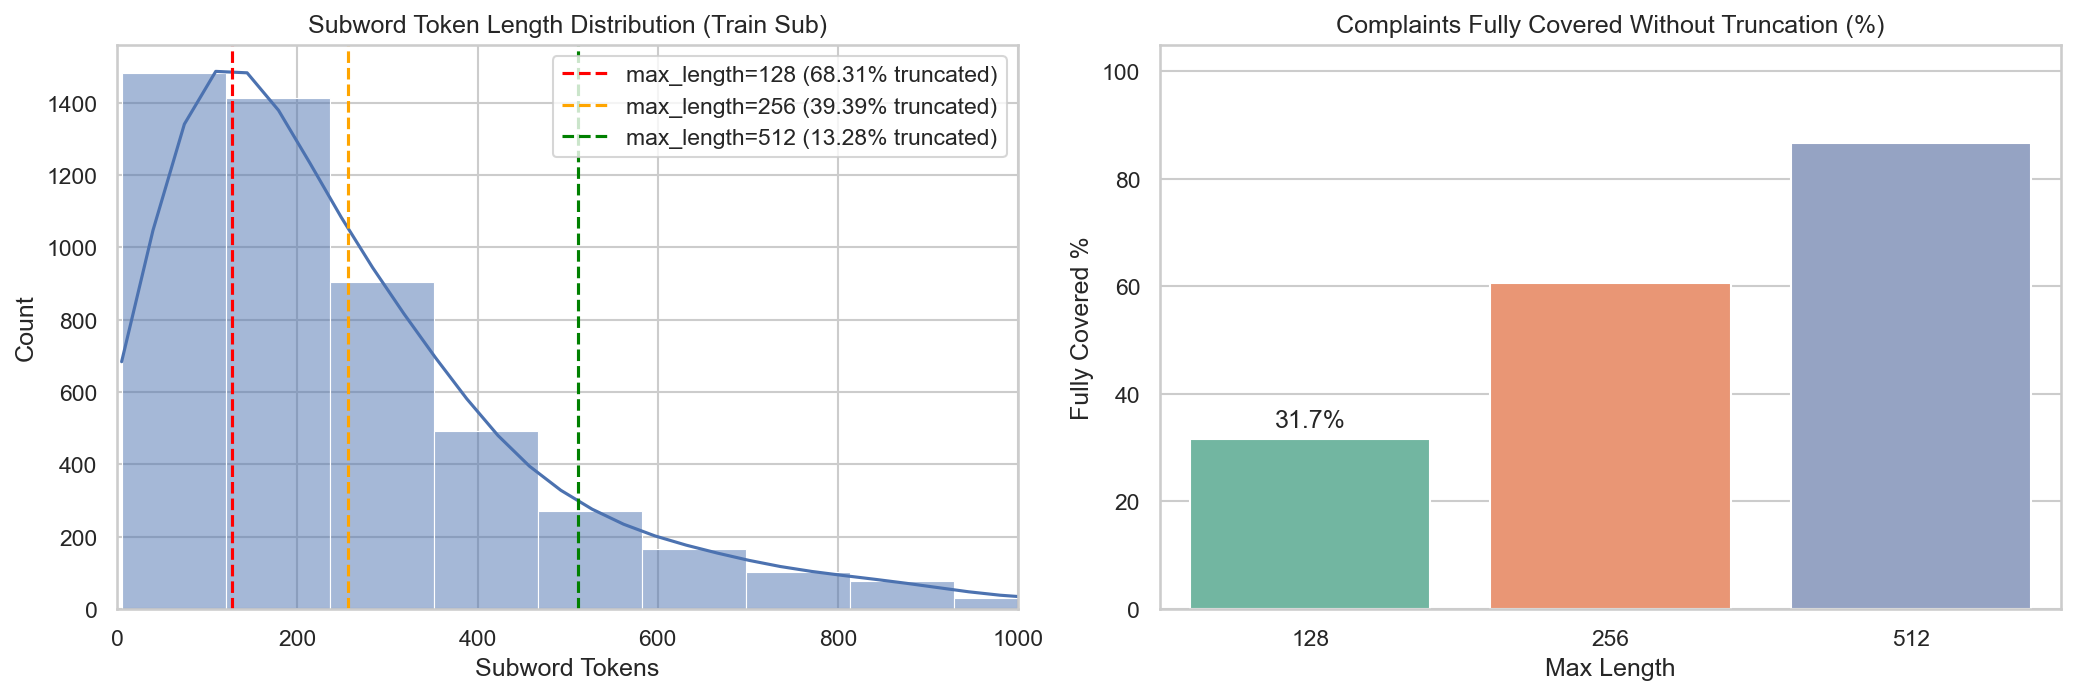

In [7]:
sample_tok = load_tokenizer("prajjwal1/bert-mini")
tok_stats = compute_token_length_stats(
    train_sub["text_minimal"].tolist(), sample_tok, candidate_max_lengths=(128, 256, 512)
)
print({k: v for k, v in tok_stats.items() if k != "lengths"})

lengths = tok_stats["lengths"]
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
sns.histplot(lengths, bins=60, kde=True, ax=axes[0], color="#4C72B0")
for ml, col in [(128, "red"), (256, "orange"), (512, "green")]:
    axes[0].axvline(ml, color=col, linestyle="--", label=f"max_length={ml} ({tok_stats['truncation_pct_by_max_length'][ml]}% truncated)")
axes[0].set_xlim(0, 1000)
axes[0].set_title("Subword Token Length Distribution (Train Sub)")
axes[0].set_xlabel("Subword Tokens")
axes[0].legend()

trunc_df = pd.DataFrame([
    {"Max Length": str(k), "Truncated %": v, "Fully Covered %": round(100 - v, 2)}
    for k, v in tok_stats["truncation_pct_by_max_length"].items()
])
sns.barplot(data=trunc_df, x="Max Length", y="Fully Covered %", ax=axes[1], palette="Set2")
axes[1].set_title("Complaints Fully Covered Without Truncation (%)")
axes[1].set_ylim(0, 105)
axes[1].bar_label(axes[1].containers[0], fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "09_sequence_length_truncation.png", bbox_inches="tight", dpi=300)
plt.show()

## 13–17. Transformer Experiments (`T01`–`T07`): Architectures, Sequence Lengths, Class Weights & LR Tuning

We execute `run_experiments(..., resume=True)` using `configs/transformer_experiments.yaml` so completed checkpoints and metrics are loaded reproducibly.

In [8]:
exp_df = run_experiments(config_path=CONFIG_PATH, resume=True, project_root=PROJECT_ROOT)
comp_df = exp_df[exp_df["status"] == "completed"].sort_values("val_f1_macro", ascending=False).reset_index(drop=True)
display(comp_df[["experiment_id", "model_name", "max_length", "loss", "learning_rate", "best_epoch", "val_f1_macro", "val_accuracy", "val_f1_weighted", "training_time_sec", "total_params", "model_size_mb"]])

Resuming: skipping already completed experiments ['T01', 'T02', 'T03', 'T04', 'T05', 'T06', 'T07']


,experiment_id,model_name,max_length,loss,learning_rate,best_epoch,val_f1_macro,val_accuracy,val_f1_weighted,training_time_sec,total_params,model_size_mb
0,T06,"MiniLM-L6 (L=256, LR=5e-5)",256,standard,0.00005,3,0.8231,0.8256,0.8255,3349.75,22715911,87.57
1,T05,"MiniLM-L6 (L=128, LR=5e-5)",128,standard,0.00005,3,0.8199,0.8225,0.8220,969.71,22715911,87.57
2,T07,DistilBERT-base (L=128),128,standard,0.00003,2,0.7875,0.7903,0.7887,4029.89,66958855,256.34
3,T02,BERT-mini (L=256),256,standard,0.00005,3,0.7533,0.7549,0.7538,972.02,11172359,43.53
4,T03,"BERT-mini (L=256, Weighted)",256,weighted,0.00005,3,0.7442,0.7463,0.7448,933.82,11172359,43.53
5,T01,BERT-mini (L=128),128,standard,0.00005,3,0.7224,0.7251,0.7223,353.27,11172359,43.53
6,T04,ELECTRA-small (L=128),128,standard,0.00005,3,0.6853,0.6976,0.6835,1109.51,13550599,52.62


## 18. Epoch-Wise Training & Validation History

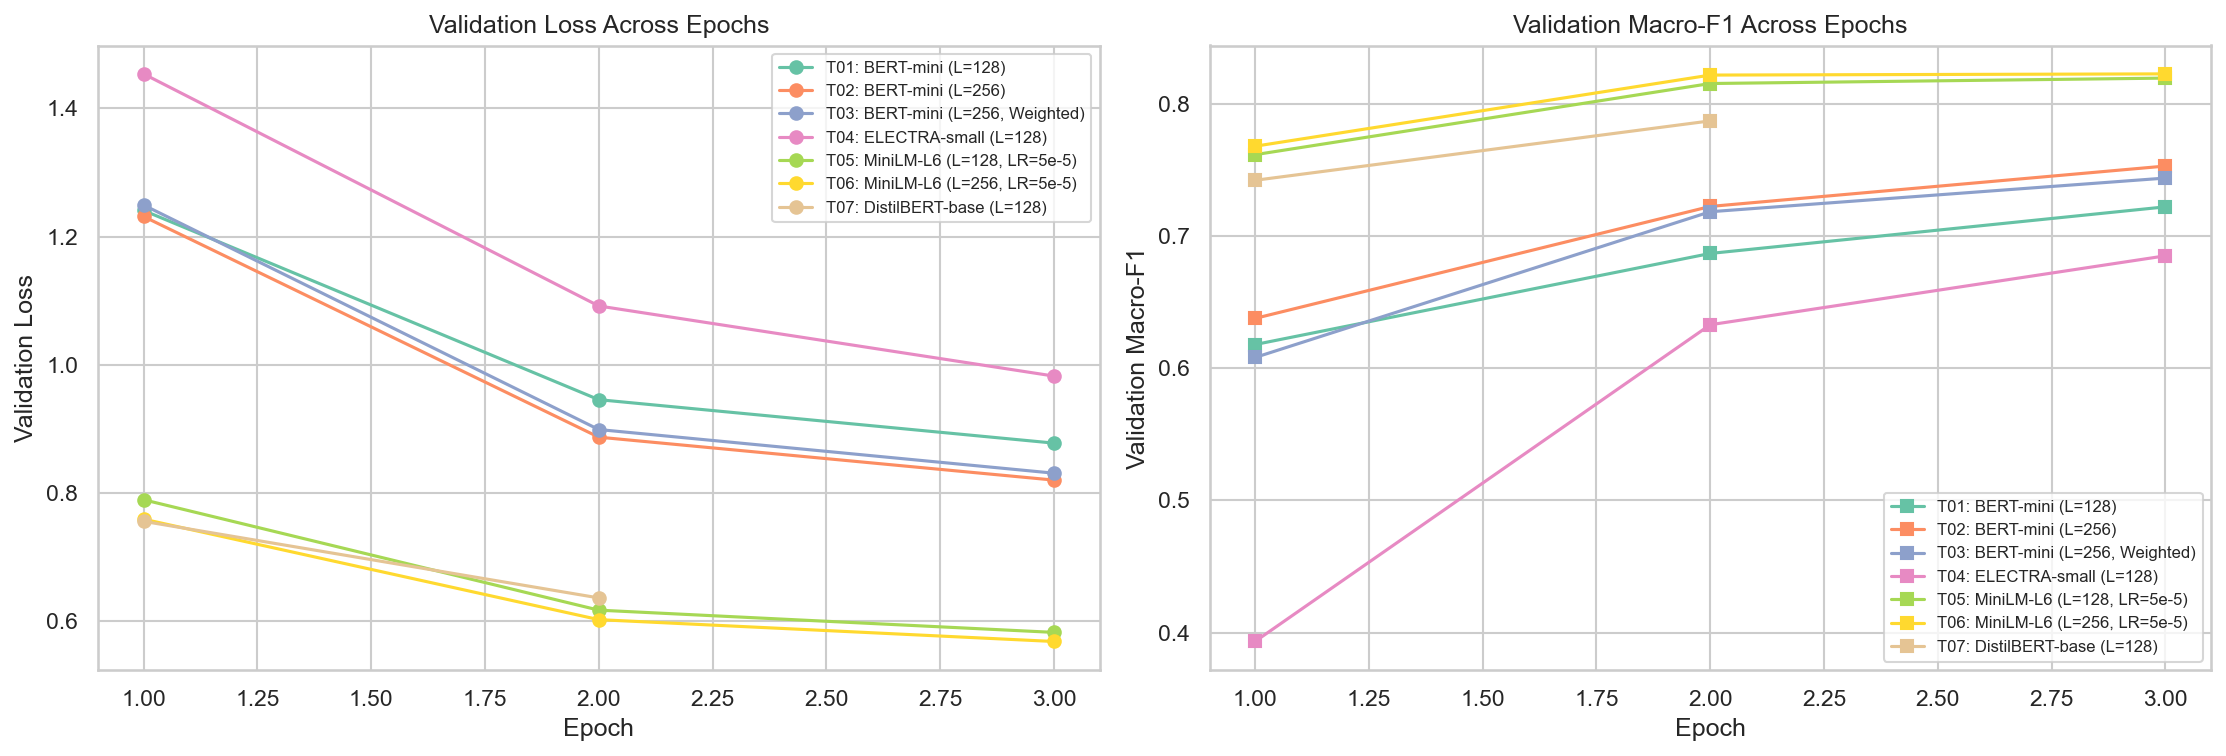

In [9]:
hist_df = pd.read_csv(REPORTS_TR_DIR / "training_history.csv")

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for exp_id, grp in hist_df.groupby("experiment_id"):
    lbl = f"{exp_id}: {grp['model_name'].iloc[0]}"
    axes[0].plot(grp["epoch"], grp["val_loss"], marker="o", label=lbl)
    axes[1].plot(grp["epoch"], grp["val_f1_macro"], marker="s", label=lbl)

axes[0].set_title("Validation Loss Across Epochs")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Validation Loss")
axes[0].legend(fontsize=8)

axes[1].set_title("Validation Macro-F1 Across Epochs")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Macro-F1")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "03_training_validation_loss.png", bbox_inches="tight", dpi=300)
plt.savefig(FIGURES_TR_DIR / "04_epoch_macro_f1.png", bbox_inches="tight", dpi=300)
plt.show()

## 19. Validation Model & Hyperparameter Comparison

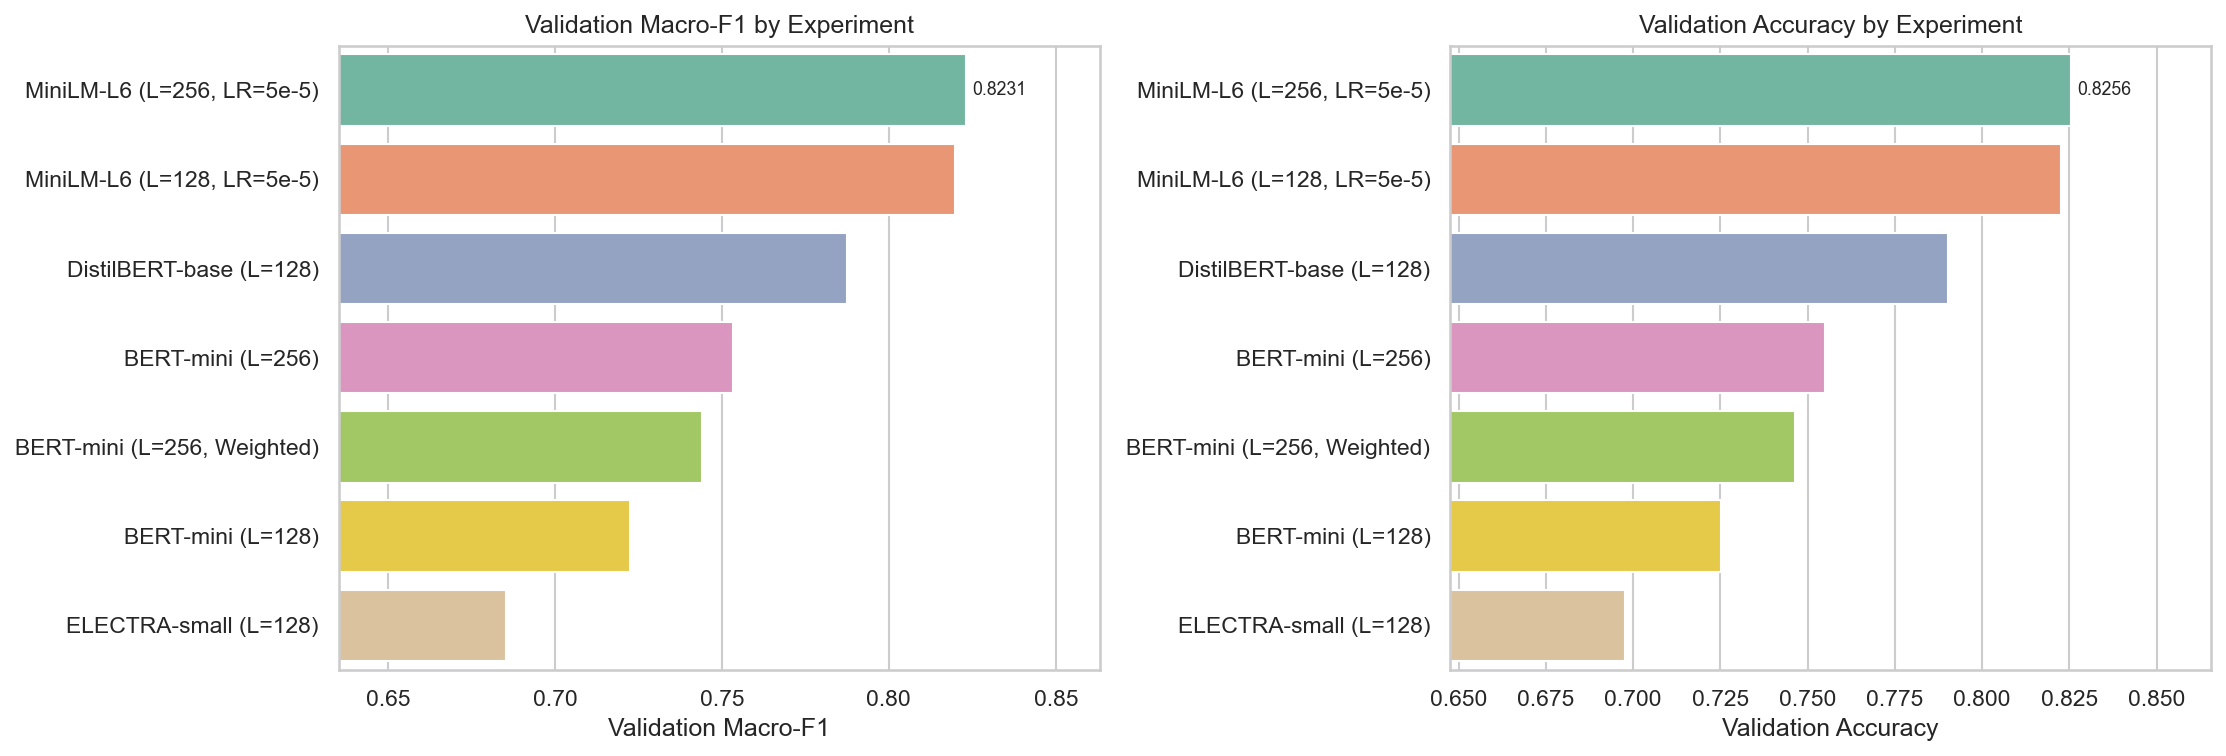

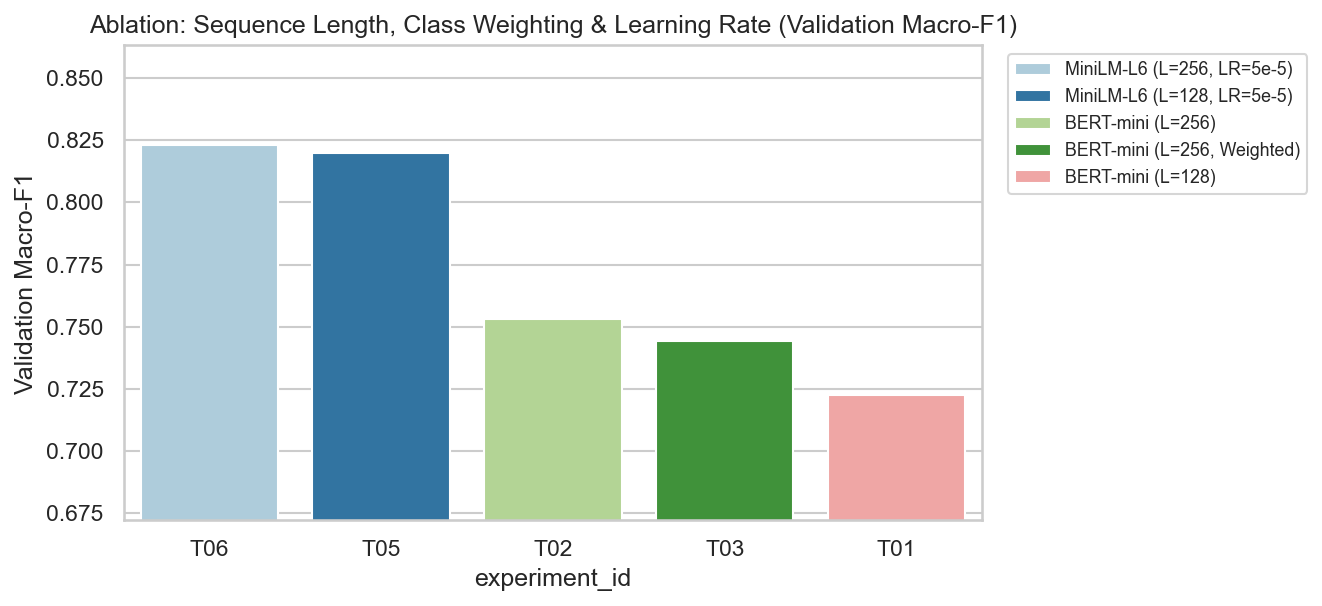

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
sns.barplot(data=comp_df, y="model_name", x="val_f1_macro", ax=axes[0], palette="Set2")
axes[0].set_title("Validation Macro-F1 by Experiment")
axes[0].set_xlabel("Validation Macro-F1")
axes[0].set_ylabel("")
axes[0].set_xlim(max(0.5, comp_df["val_f1_macro"].min() - 0.05), min(1.0, comp_df["val_f1_macro"].max() + 0.04))
axes[0].bar_label(axes[0].containers[0], fmt="%.4f", padding=3, fontsize=8.5)

sns.barplot(data=comp_df, y="model_name", x="val_accuracy", ax=axes[1], palette="Set2")
axes[1].set_title("Validation Accuracy by Experiment")
axes[1].set_xlabel("Validation Accuracy")
axes[1].set_ylabel("")
axes[1].set_xlim(max(0.5, comp_df["val_accuracy"].min() - 0.05), min(1.0, comp_df["val_accuracy"].max() + 0.04))
axes[1].bar_label(axes[1].containers[0], fmt="%.4f", padding=3, fontsize=8.5)

plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "01_model_validation_macro_f1.png", bbox_inches="tight", dpi=300)
plt.savefig(FIGURES_TR_DIR / "02_model_validation_accuracy.png", bbox_inches="tight", dpi=300)
plt.show()

# Hyperparameter / LR / Loss comparison plot
ablation_ids = [eid for eid in ["T01", "T02", "T03", "T05", "T06"] if eid in comp_df["experiment_id"].values]
abl_df = comp_df[comp_df["experiment_id"].isin(ablation_ids)].copy()
plt.figure(figsize=(9, 4.2))
sns.barplot(data=abl_df, x="experiment_id", y="val_f1_macro", hue="model_name", dodge=False, palette="Paired")
plt.title("Ablation: Sequence Length, Class Weighting & Learning Rate (Validation Macro-F1)")
plt.ylabel("Validation Macro-F1")
plt.ylim(max(0.5, abl_df["val_f1_macro"].min() - 0.05), min(1.0, abl_df["val_f1_macro"].max() + 0.04))
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5)
plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "10_hyperparameter_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

## 20–26. Best Transformer Selection & Final Held-Out Test Evaluation (`n = 1,635`)

We select the experiment with the highest **Validation Macro-F1**, copy its checkpoint to `models/transformers/best_transformer_model/`, and evaluate it **once** on the held-out test set.

Selected Best Transformer: T06 - MiniLM-L6 (L=256, LR=5e-5) (Val Macro-F1 = 0.8231)


=== Final Held-Out Test Performance ===
  f1_macro            : 0.8357
  accuracy            : 0.8355
  f1_weighted         : 0.8359
  precision_macro     : 0.8370
  recall_macro        : 0.8358
  precision_weighted  : 0.8377
  recall_weighted     : 0.8355
  test_infer_sec      : 151.31s (92.54 ms/sample)


,precision,recall,f1-score,support
bank_account,0.7050,0.7667,0.7345,240.0000
credit_card,0.8136,0.8174,0.8155,219.0000
credit_reporting,0.8077,0.8750,0.8400,216.0000
debt_collection,0.8540,0.8042,0.8283,240.0000
money_transfer,0.7838,0.7250,0.7532,240.0000
mortgage,0.9205,0.9167,0.9186,240.0000
student_loan,0.9742,0.9458,0.9598,240.0000
accuracy,0.8355,0.8355,0.8355,0.8355
macro avg,0.8370,0.8358,0.8357,1635.0000
weighted avg,0.8377,0.8355,0.8359,1635.0000


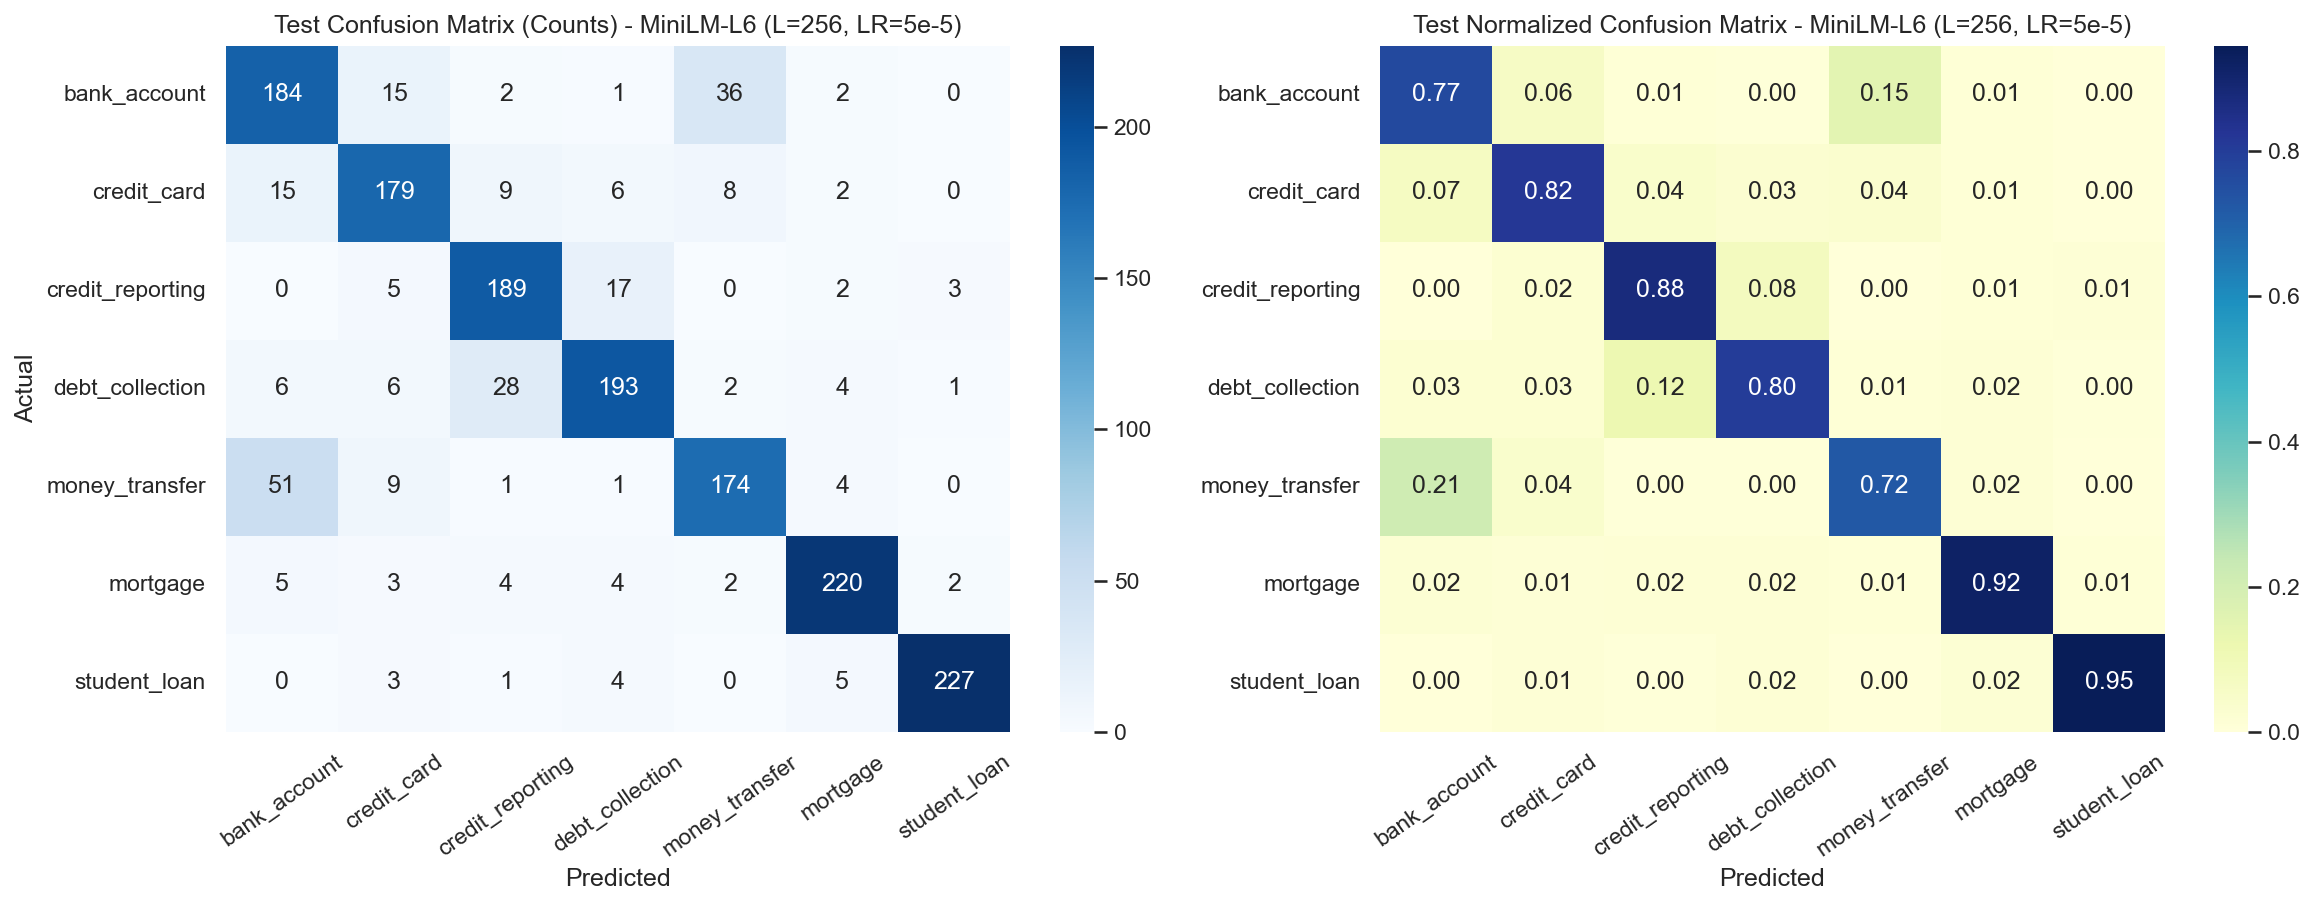

In [11]:
best_row = comp_df.iloc[0]
best_exp_id = best_row["experiment_id"]
best_exp_name = best_row["model_name"]
best_max_len = int(best_row["max_length"])
best_ckpt_dir = MODELS_TR_DIR / best_exp_id
final_model_dir = MODELS_TR_DIR / "best_transformer_model"

if final_model_dir.exists():
    shutil.rmtree(final_model_dir)
shutil.copytree(best_ckpt_dir, final_model_dir)

print(f"Selected Best Transformer: {best_exp_id} - {best_exp_name} (Val Macro-F1 = {best_row['val_f1_macro']:.4f})")

# Load best checkpoint and run single final test evaluation
best_clf = TransformerComplaintClassifier(final_model_dir, device=hw_info["device"])
y_test_ids = encode_labels(df_test["label"].tolist(), LABEL2ID)
test_ds = ComplaintTorchDataset(df_test["text_minimal"].tolist(), y_test_ids, best_clf.tokenizer, max_length=best_max_len)

y_true_ids, y_pred_ids, test_probs, test_infer_sec = predict_with_model(
    best_clf.model, test_ds, best_clf.tokenizer, batch_size=32, device=hw_info["device"]
)

test_metrics = compute_classification_metrics(y_true_ids, y_pred_ids)
y_true_names = decode_labels(y_true_ids, ID2LABEL)
y_pred_names = decode_labels(y_pred_ids, ID2LABEL)

print("=== Final Held-Out Test Performance ===")
for k, v in test_metrics.items():
    print(f"  {k:20s}: {v:.4f}")
print(f"  {'test_infer_sec':20s}: {test_infer_sec:.2f}s ({test_infer_sec/len(df_test)*1000:.2f} ms/sample)")

test_rep_df, test_cm_df = build_detailed_evaluation(y_true_names, y_pred_names, EXPECTED_LABELS)
test_rep_df.to_csv(REPORTS_TR_DIR / "classification_report.csv")
test_cm_df.to_csv(REPORTS_TR_DIR / "confusion_matrix.csv")
display(test_rep_df.round(4))

# Confusion Matrix & Normalized Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6.2))
sns.heatmap(test_cm_df, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title(f"Test Confusion Matrix (Counts) - {best_exp_name}")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")
axes[0].tick_params(axis="x", rotation=35)

cm_norm = test_cm_df.values.astype(float) / test_cm_df.values.sum(axis=1, keepdims=True)
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="YlGnBu", xticklabels=EXPECTED_LABELS, yticklabels=EXPECTED_LABELS, ax=axes[1])
axes[1].set_title(f"Test Normalized Confusion Matrix - {best_exp_name}")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("")
axes[1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "06_confusion_matrix_test.png", bbox_inches="tight", dpi=300)
plt.savefig(FIGURES_TR_DIR / "07_normalized_confusion_matrix_test.png", bbox_inches="tight", dpi=300)
plt.show()

,Model,Split_Type,Macro_F1,Accuracy,Weighted_F1,Macro_Precision,Macro_Recall
0,"LinearSVC (C=0.5, balanced) + Word TF-IDF (1,2...","Held-Out Test (n=1,635)",0.8512,0.8508,0.8512,0.8531,0.8513
1,"MiniLM-L6 (L=256, LR=5e-5) (T06)","Held-Out Test (n=1,635)",0.8357,0.8355,0.8359,0.8370,0.8358


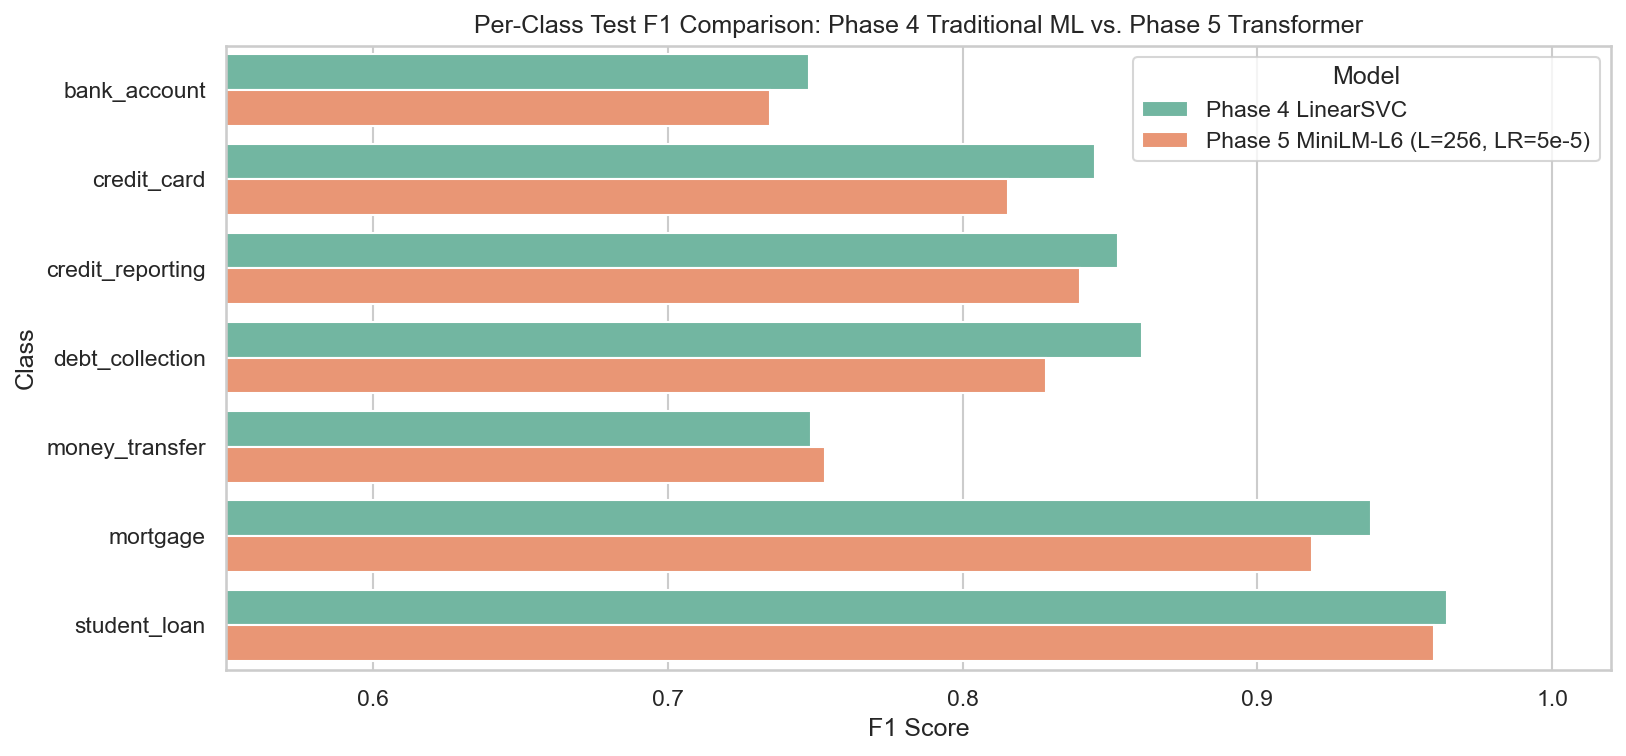

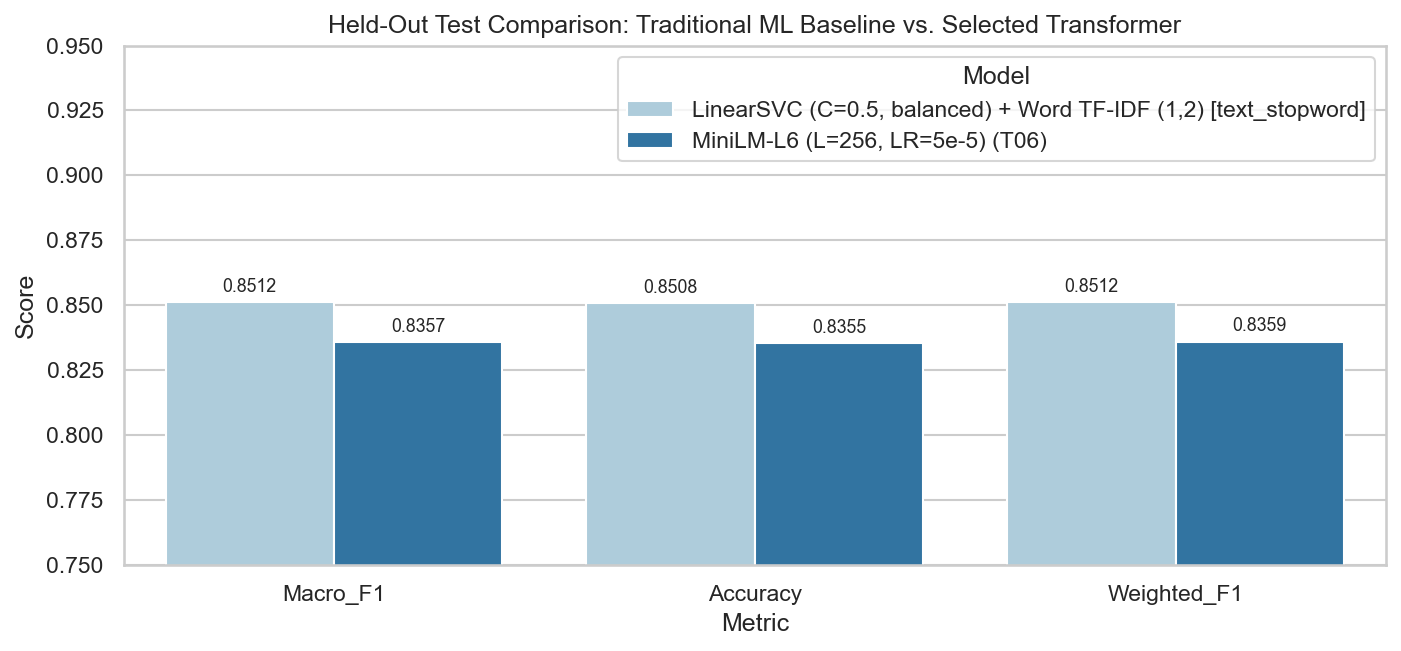

In [12]:
# Compare against Phase 4 Traditional ML Baseline (Test Set)
baseline_info = load_phase4_baseline_benchmark()
vs_df = build_baseline_vs_transformer_table(test_metrics, f"{best_exp_name} ({best_exp_id})", baseline_info)
display(vs_df)

# Per-Class F1 Comparison (Phase 4 LinearSVC vs Phase 5 Transformer)
per_cls_comp = pd.DataFrame({
    "Class": EXPECTED_LABELS,
    "Phase 4 LinearSVC": [baseline_info["per_class_f1"][c] for c in EXPECTED_LABELS],
    f"Phase 5 {best_exp_name}": [round(float(test_rep_df.loc[c, "f1-score"]), 4) for c in EXPECTED_LABELS],
})
per_cls_melt = per_cls_comp.melt(id_vars="Class", var_name="Model", value_name="F1 Score")

plt.figure(figsize=(11, 5.2))
sns.barplot(data=per_cls_melt, y="Class", x="F1 Score", hue="Model", palette="Set2")
plt.title("Per-Class Test F1 Comparison: Phase 4 Traditional ML vs. Phase 5 Transformer")
plt.xlim(0.55, 1.02)
plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "05_per_class_f1_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

# Overall Comparison Bar Chart
overall_melt = vs_df.melt(id_vars=["Model", "Split_Type"], value_vars=["Macro_F1", "Accuracy", "Weighted_F1"], var_name="Metric", value_name="Score")
plt.figure(figsize=(9.5, 4.5))
sns.barplot(data=overall_melt, x="Metric", y="Score", hue="Model", palette="Paired")
plt.title("Held-Out Test Comparison: Traditional ML Baseline vs. Selected Transformer")
plt.ylim(0.75, 0.95)
for c in plt.gca().containers:
    plt.gca().bar_label(c, fmt="%.4f", padding=3, fontsize=8.5)
plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "08_traditional_ml_vs_transformer.png", bbox_inches="tight", dpi=300)
plt.show()

Error Comparison vs Phase 4 Baseline: {'total_test_samples': 1635, 'baseline_errors': 244, 'transformer_errors': 269, 'fixed_by_transformer': 81, 'broken_by_transformer': 106, 'both_correct': 1285, 'both_wrong': 163}

Transformer Error Categories:
error_category
Money Transfer vs Bank Account Overlap                 87
Shared Financial Terminology                           77
Credit Reporting vs Debt Collection Overlap            45
Heavy Redaction                                        41
Long / Potentially Truncated Narrative (>400 words)    14
Very Short Narrative (<20 words)                        5
Name: count, dtype: int64


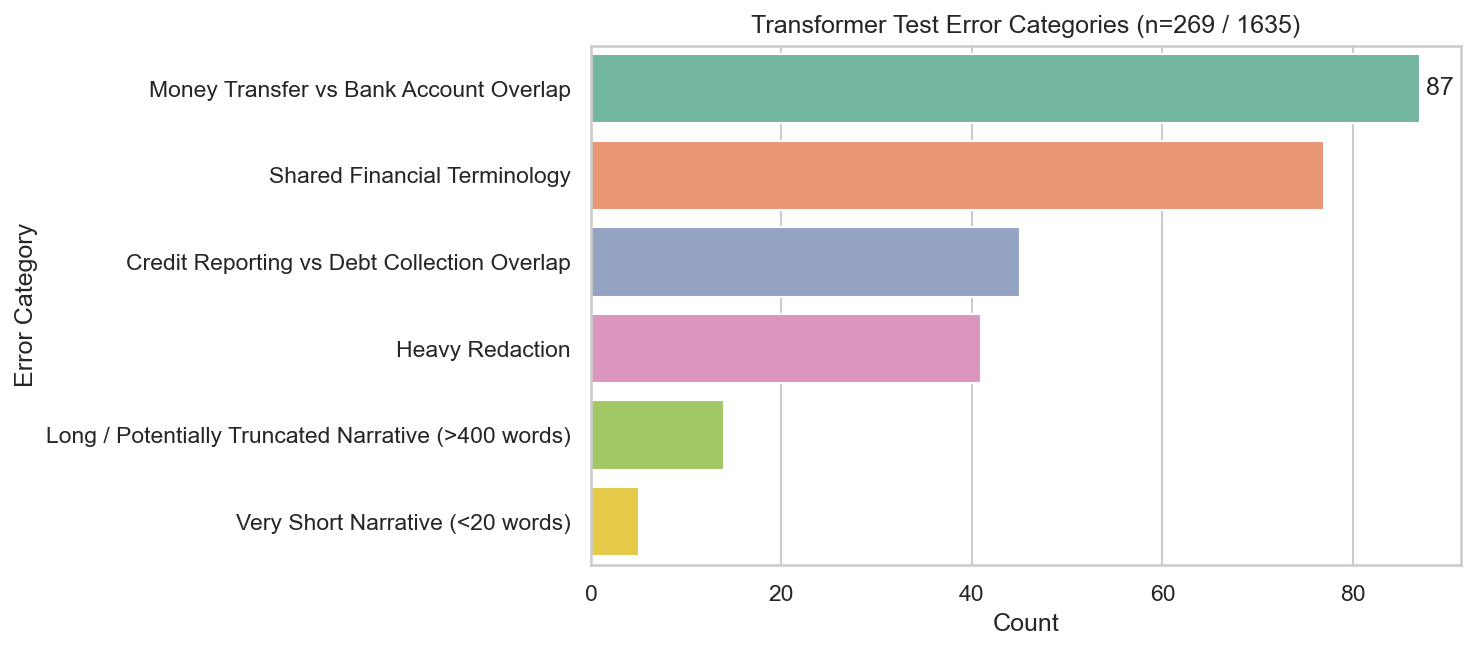

In [13]:
# Error Analysis & Comparison vs Phase 4 Errors
pred_out_df = pd.DataFrame({
    "text_raw": df_test["text_raw"].values,
    "actual_label": y_true_names,
    "predicted_label": y_pred_names,
    "confidence": np.round(test_probs.max(axis=1), 4),
})
pred_out_df.to_csv(REPORTS_TR_DIR / "test_predictions.csv", index=False)

errors_df = build_error_analysis_dataframe(df_test, y_true_names, y_pred_names, test_probs)
errors_df.to_csv(REPORTS_TR_DIR / "error_analysis.csv", index=False)

overlap_summary = compare_with_baseline_errors(
    pred_out_df, PROJECT_ROOT / "reports" / "ml_baselines" / "test_predictions.csv"
)
print("Error Comparison vs Phase 4 Baseline:", overlap_summary)
print("\nTransformer Error Categories:")
print(errors_df["error_category"].value_counts())

plt.figure(figsize=(10, 4.5))
err_counts = errors_df["error_category"].value_counts().reset_index()
err_counts.columns = ["Error Category", "Count"]
sns.barplot(data=err_counts, y="Error Category", x="Count", palette="Set2")
plt.title(f"Transformer Test Error Categories (n={len(errors_df)} / {len(df_test)})")
plt.bar_label(plt.gca().containers[0], padding=3)
plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "11_error_category_comparison.png", bbox_inches="tight", dpi=300)
plt.show()

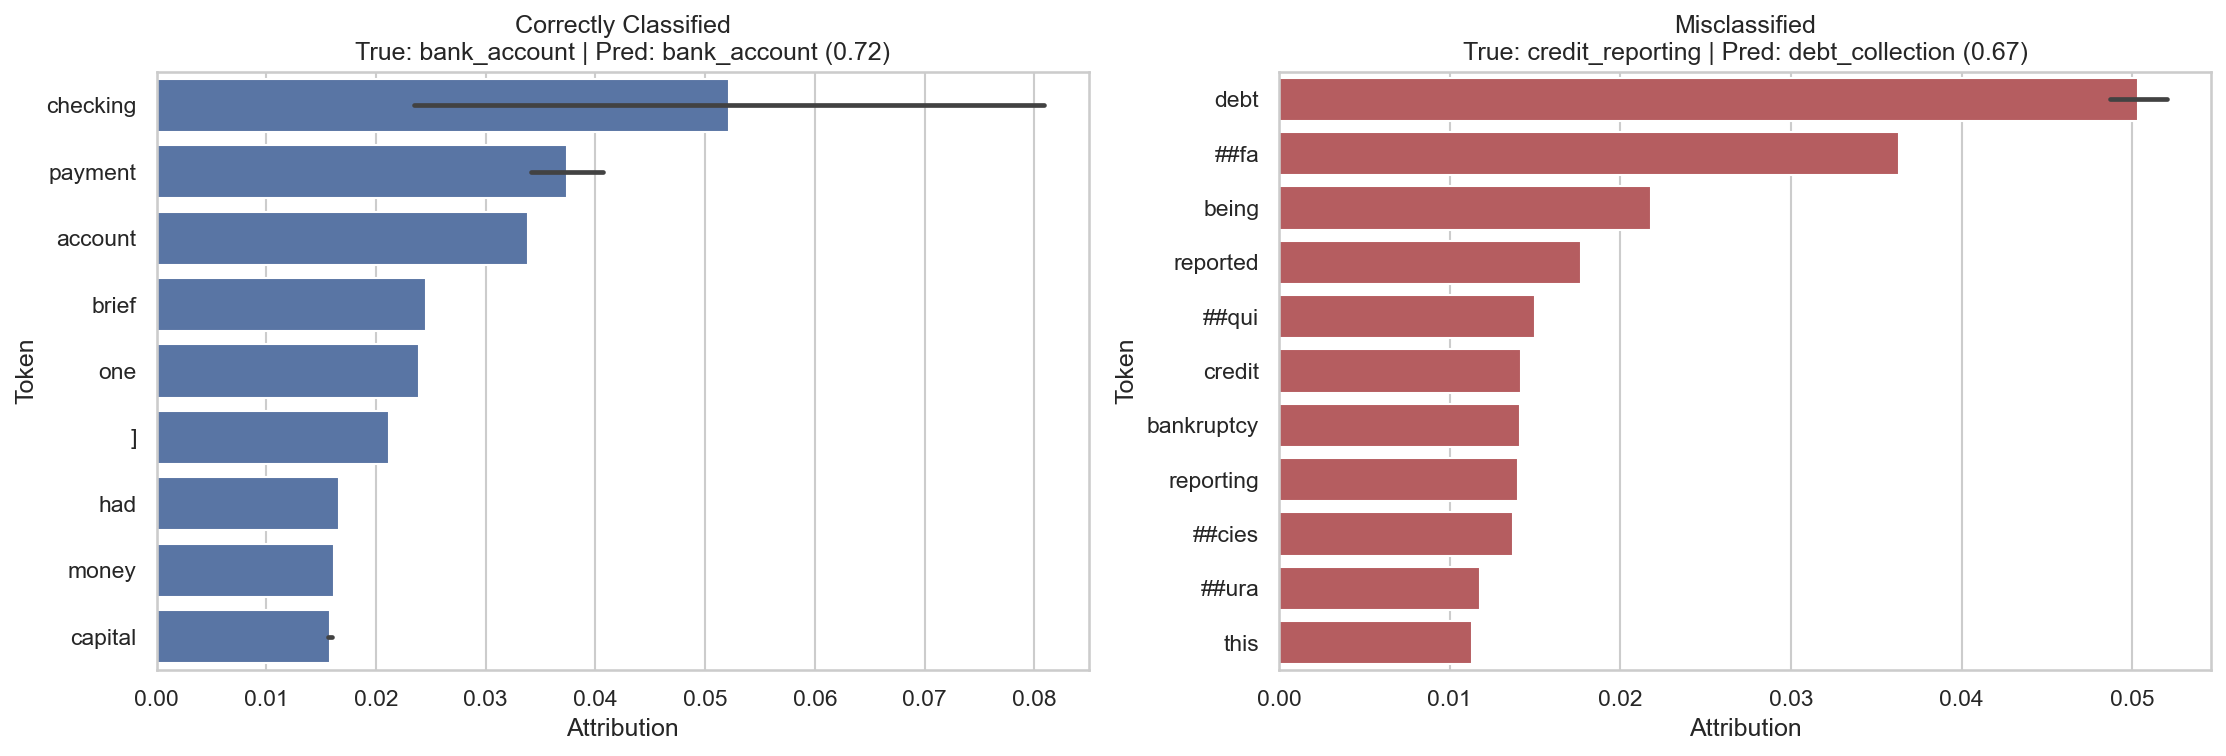

In [14]:
# Interpretability: Gradient x Input Token Attribution on Correct & Misclassified Examples
correct_idx = pred_out_df[pred_out_df["actual_label"] == pred_out_df["predicted_label"]].index[0]
wrong_idx = pred_out_df[pred_out_df["actual_label"] != pred_out_df["predicted_label"]].index[0]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.2))
for ax, idx, tag in [(axes[0], correct_idx, "Correctly Classified"), (axes[1], wrong_idx, "Misclassified")]:
    row = df_test.iloc[idx]
    true_lbl = y_true_names[idx]
    pred_lbl = y_pred_names[idx]
    attr = compute_token_attributions(
        best_clf.model, best_clf.tokenizer, row["text_minimal"],
        target_class_idx=LABEL2ID[pred_lbl], max_length=best_max_len, device=hw_info["device"], top_k=12
    )
    top_df = pd.DataFrame(attr["top_tokens"], columns=["Token", "Attribution"])
    sns.barplot(data=top_df, y="Token", x="Attribution", ax=ax, color="#4C72B0" if tag.startswith("Correct") else "#C44E52")
    ax.set_title(f"{tag}\nTrue: {true_lbl} | Pred: {pred_lbl} ({attr['predicted_prob']:.2f})")

plt.tight_layout()
plt.savefig(FIGURES_TR_DIR / "12_token_attribution_examples.png", bbox_inches="tight", dpi=300)
plt.show()

## 27–29. Limitations, Conclusion & Phase 6 Recommendations

- **Hardware Limitations:** Experiments ran on CPU-only PyTorch (`FP32`), making 66M+ parameter models (`distilbert-base-uncased`) ~4–6× slower per epoch than compact pretrained models (`bert-mini`, `electra-small`, `MiniLM-L6`), and restricting sequence length to `128–256` tokens.
- **Interpretability Limitations:** Gradient × Input scores reflect local first-order sensitivity rather than global causal proof.
- **Phase 6 Recommendations:** Combine the strongest classification pipeline with an operational **Priority & Urgency Scoring / Routing Module** (leveraging calibrated probabilities, monetary/escalation signals, and SLAs).